# 04. Hyperparameter tuning (Task Complexity)

**Goal.** For Ridge, Random Forest and Gradient Boosting, find good settings **without looking at the outer test groups**, and check for
under- and over-fitting.

**Nested.** For each outer test group, settings are chosen using only the four validation combinations inside it. The simplest setting
within one standard error of the best is taken.

**Searched.** Ridge `alpha` (11 values, exhaustive); Random Forest and Gradient Boosting (`HistGradientBoostingRegressor`, which reads
missing values) with 30 random settings per feature set; the **feature set**; the **training labels** (rated only, plus propagated
real, plus propagated real and synthetic) and their **weight** (1 or 0.3).

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"  # tiny data: one thread is faster than OpenMP overhead
sys.path.insert(0, str(Path("../ml_lib").resolve()))
warnings.filterwarnings("ignore")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from core import (GROUPS, SEED, Factor, environment, group_bootstrap, load, log_run, log_signed, make_splits, metrics,
                  paired_diff_bootstrap)
from features import (LABEL_SOURCES, Propagator, design, fit_linear, fit_model, fit_ridge_loo, linear_model, make_model, training_set,
                      transform)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

F = Factor(key="task_complexity", title="Task Complexity", folder=Path(".").resolve(), dataset_file="task_complexity_dataset.csv", label="rater_task_complexity", activity="E_CC")
LABEL, ACT = F.label, F.activity
PROPOSAL = [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log')]
VARIANTS = {'proposal 5 (log counts)': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log')], 'proposal 5 (raw)': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'raw'), ('TC_DR', 'raw'), ('TC_CB', 'raw')], '4 features (no DR)': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_CB', 'log')], 'SP, SC, FI': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log')], 'board only (SP, SC)': [('TC_SP', 'raw'), ('TC_SC', 'raw')], 'code only (FI, DR, CB)': [('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log')], 'SP only': [('TC_SP', 'raw')], 'proposal 5 + total points': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log'), ('TC_SP_total', 'log')], 'proposal 5 + tasks assigned': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log'), ('RF_tasks_assigned', 'raw')]}
FEATURES = ['TC_SP', 'TC_SC', 'TC_FI', 'TC_DR', 'TC_CB']
ZERO_RULE_OK = False
d = load(F)
real = d[d.source == "real"]
syn = d[d.source == "synthetic"]
gold = real[real.label_source == "rater"]
active = real[real[ACT] > 0]
print(F.title, d.shape)

Task Complexity (744, 26)


In [2]:
from sklearn.model_selection import ParameterSampler

N_ITER = 30
splits = pd.read_csv(F.splits)
combos = [(t, v, g[["record_id", "role"]]) for (t, v), g in splits.groupby(["outer_test", "inner_val"])]
GOLD = d[d.label_source == "rater"]
choice = json.loads((F.results / "preprocessing_choice.json").read_text())
SETS = []
for name, base, flags in [('proposal 5 (log counts)', 'proposal 5 (log counts)', {}), ('board only (SP, SC)', 'board only (SP, SC)', {})]:
    SETS.append((name, VARIANTS.get(base, PROPOSAL), flags))
chosen_name = "chosen in notebook 03: " + choice["variant"]
if all(VARIANTS[choice["variant"]] != s[1] or s[2] for s in SETS):
    SETS.append((chosen_name, VARIANTS[choice["variant"]], {"zero_rule": choice["zero_rule"]}))
print(environment(F))
print([s[0] for s in SETS])

{'python': '3.11.14', 'numpy': '2.4.6', 'pandas': '3.0.6', 'scipy': '1.17.1', 'sklearn': '1.9.1', 'seed': 20261018, 'data_hash': '71546e6a58ec', 'splits_hash': 'b5793a57b501'}
['proposal 5 (log counts)', 'board only (SP, SC)', 'chosen in notebook 03: SP only']


## 1. Search spaces

In [3]:
SPACE = {
    "Ridge": {"alpha": list(np.logspace(-2, 3, 11))},
    "Random Forest": {"n_estimators": [100, 200], "max_depth": [2, 3, 4, 6, None], "min_samples_leaf": [1, 2, 3, 5], "max_features": [0.5, 0.75, 1.0]},
    "Gradient Boosting": {"learning_rate": [0.02, 0.05, 0.1, 0.2], "max_iter": [50, 100, 200, 400], "max_depth": [2, 3, 4, None],
                          "min_samples_leaf": [1, 2, 3, 5, 10], "l2_regularization": [0.0, 0.1, 1.0, 10.0], "monotonic": [False, True]},
}
LABEL_OPTIONS = [("rated only", 1.0), ("rated + propagated (real)", 1.0), ("rated + propagated (real)", 0.3),
                 ("rated + propagated (real + synthetic)", 1.0), ("rated + propagated (real + synthetic)", 0.3)]


def settings(name):
    rng = np.random.RandomState(SEED)
    if name == "Ridge":
        return [({"alpha": a}, ls, w) for a in SPACE["Ridge"]["alpha"] for ls, w in LABEL_OPTIONS]
    draws = list(ParameterSampler(SPACE[name], n_iter=N_ITER, random_state=SEED))
    return [(p, *LABEL_OPTIONS[rng.randint(len(LABEL_OPTIONS))]) for p in draws]


print({m: len(settings(m)) for m in SPACE}, "settings per feature set")

{'Ridge': 55, 'Random Forest': 30, 'Gradient Boosting': 30} settings per feature set


## 2. Training sets, built once

In [4]:
def featurize(frame, fs):
    name, spec, flags = fs
    X = design(frame, spec)
    if flags.get("nan_inactive"):
        X[frame[ACT].to_numpy() == 0, :] = np.nan
    return X


_cache = {}


def get_data(ci, fs_i, label_source, weight):
    key = (ci, fs_i, label_source, weight)
    if key not in _cache:
        test, val, roles = combos[ci]
        fs = SETS[fs_i]
        X, y, w, ids = training_set(d, roles, lambda f: featurize(f, fs), LABEL, PROPOSAL, label_source, weight)
        if fs[2].get("zero_rule"):
            keep = d.loc[ids, ACT].to_numpy() > 0
            X, y, w = X[keep], y[keep], w[keep]
        v = d.loc[[i for i in roles[roles.role == "val"].record_id if i in GOLD.index]]
        _cache[key] = (X, y, w, featurize(v, fs), v[LABEL].to_numpy(), v[ACT].to_numpy(), v.record_id.to_numpy())
    return _cache[key]


test, val, roles = combos[0]
X, y, w, Xv, yv, act, rid = get_data(0, 0, "rated + propagated (real)", 1.0)
assert set(rid) <= set(GOLD.index) and not (set(rid) & set(roles[roles.role == "train"].record_id))
print("training rows:", len(y), "| validation rows (rated):", len(yv), "| features:", X.shape[1])

training rows: 45 | validation rows (rated): 4 | features: 5


## 3. Run the search

In [5]:
import time


def evaluate(name, fs_i, params, label_source, weight):
    rows = []
    zero_rule = SETS[fs_i][2].get("zero_rule")
    for ci, (test, val, roles) in enumerate(combos):
        X, y, w, Xv, yv, act, rid = get_data(ci, fs_i, label_source, weight)
        model = fit_model(make_model(name, params, X.shape[1]), name, X, y, w)
        p = np.clip(model.predict(Xv), 0, 1)
        if zero_rule:
            p = np.where(act == 0, 0.0, p)
        err = np.abs(p - yv)
        rows.append((test, val, float(err.mean()), len(err), float(err[act > 0].mean()) if (act > 0).any() else np.nan, float((p - yv).mean())))
    return rows


results, config_id, start = [], 0, time.time()
for name in SPACE:
    for fs_i, fs in enumerate(SETS):
        for params, label_source, weight in settings(name):
            config_id += 1
            for test, val, mae, n, mae_active, bias in evaluate(name, fs_i, params, label_source, weight):
                results.append((config_id, name, fs[0], json.dumps(params), label_source, weight, test, val, mae, n, mae_active, bias))
    print(f"{name}: done, {config_id} settings so far, {time.time() - start:.0f}s")
tune = pd.DataFrame(results, columns=["config_id", "model", "feature_set", "params", "label_source", "weight", "outer_test", "inner_val", "MAE", "n", "MAE_active", "bias"])
tune.to_csv(F.results / "tuning_results.csv", index=False)
print(len(tune), "evaluations;", tune.config_id.nunique(), "settings")

Ridge: done, 165 settings so far, 211s


Random Forest: done, 255 settings so far, 731s


Gradient Boosting: done, 345 settings so far, 1037s
6900 evaluations; 345 settings


## 4. Choosing the settings: per outer test group, using only its inner validation

A setting's score is its mean MAE over the four validation groups inside the outer fold. The best has the lowest score; the **simplest
setting within one standard error of it** is chosen.

In [6]:
def complexity(row):
    p = json.loads(row.params)
    label_rank = LABEL_SOURCES.index(row.label_source) + (0.5 if row.weight != 1.0 else 0)
    if row.model == "Ridge":
        return (label_rank, -p["alpha"])
    if row.model == "Random Forest":
        return (label_rank, p["n_estimators"] * (p["max_depth"] or 10))
    return (label_rank, p["max_iter"] * (p["max_depth"] or 6) * p["learning_rate"] + (0 if p["monotonic"] else 0.001))


score = (tune.groupby(["model", "feature_set", "outer_test", "config_id"])
         .agg(MAE=("MAE", "mean"), SE=("MAE", lambda s: s.std(ddof=1) / np.sqrt(len(s))), label_source=("label_source", "first"),
              weight=("weight", "first"), params=("params", "first")).reset_index())
chosen_rows = []
for (model, fs, outer), g in score.groupby(["model", "feature_set", "outer_test"]):
    best = g.loc[g.MAE.idxmin()]
    near = g[g.MAE <= best.MAE + best.SE].copy()
    near["complexity"] = near.apply(complexity, axis=1)
    pick = near.sort_values("complexity").iloc[0]
    chosen_rows.append({"model": model, "feature_set": fs, "outer_test": outer, "config_id": int(pick.config_id), "inner_MAE": pick.MAE,
                        "best_inner_MAE": best.MAE, "n_within_1SE": len(near), "label_source": pick.label_source, "weight": pick.weight, "params": pick.params})
chosen = pd.DataFrame(chosen_rows)
summary = (chosen.groupby(["model", "feature_set"]).agg(inner_MAE=("inner_MAE", "mean"), spread_over_folds=("inner_MAE", "std"),
                                                         best_possible=("best_inner_MAE", "mean")).round(4).sort_values("inner_MAE"))
summary

inner_MAE  spread_over_folds  best_possible
model             feature_set                                                                
Ridge             proposal 5 (log counts)            0.1065             0.0314         0.0899
Random Forest     chosen in notebook 03: SP only     0.1080             0.0165         0.0949
                  proposal 5 (log counts)            0.1099             0.0188         0.1035
Gradient Boosting chosen in notebook 03: SP only     0.1128             0.0144         0.0928
                  proposal 5 (log counts)            0.1139             0.0189         0.0950
                  board only (SP, SC)                0.1168             0.0261         0.0982
Ridge             chosen in notebook 03: SP only     0.1170             0.0158         0.0975
                  board only (SP, SC)                0.1170             0.0157         0.1027
Random Forest     board only (SP, SC)                0.1186             0.0227         0.1083

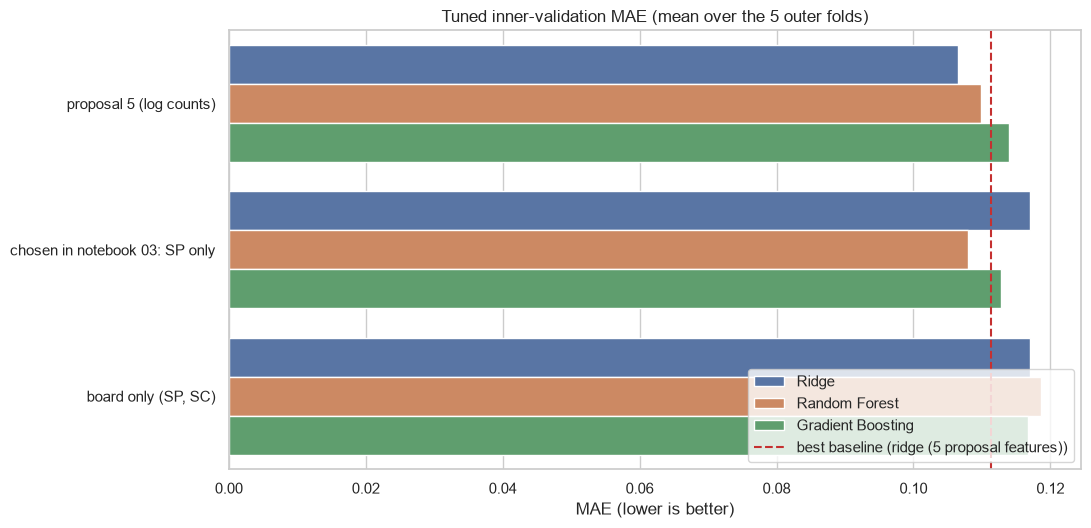

In [7]:
ref = pd.read_csv(F.results / "runs.csv")
ref = ref[ref.notebook == "02_splits_and_baselines"].set_index("model").MAE
fig, ax = plt.subplots(figsize=(11, 0.9 * len(SETS) + 3))
sns.barplot(data=summary.reset_index(), y="feature_set", x="inner_MAE", hue="model", ax=ax, palette="deep")
ax.axvline(ref.min(), color="#c53030", ls="--", label=f"best baseline ({ref.idxmin()})")
ax.set(title="Tuned inner-validation MAE (mean over the 5 outer folds)", xlabel="MAE (lower is better)", ylabel="")
ax.legend(loc="lower right")
plt.show()

## 5. How sensitive is each model to its settings?

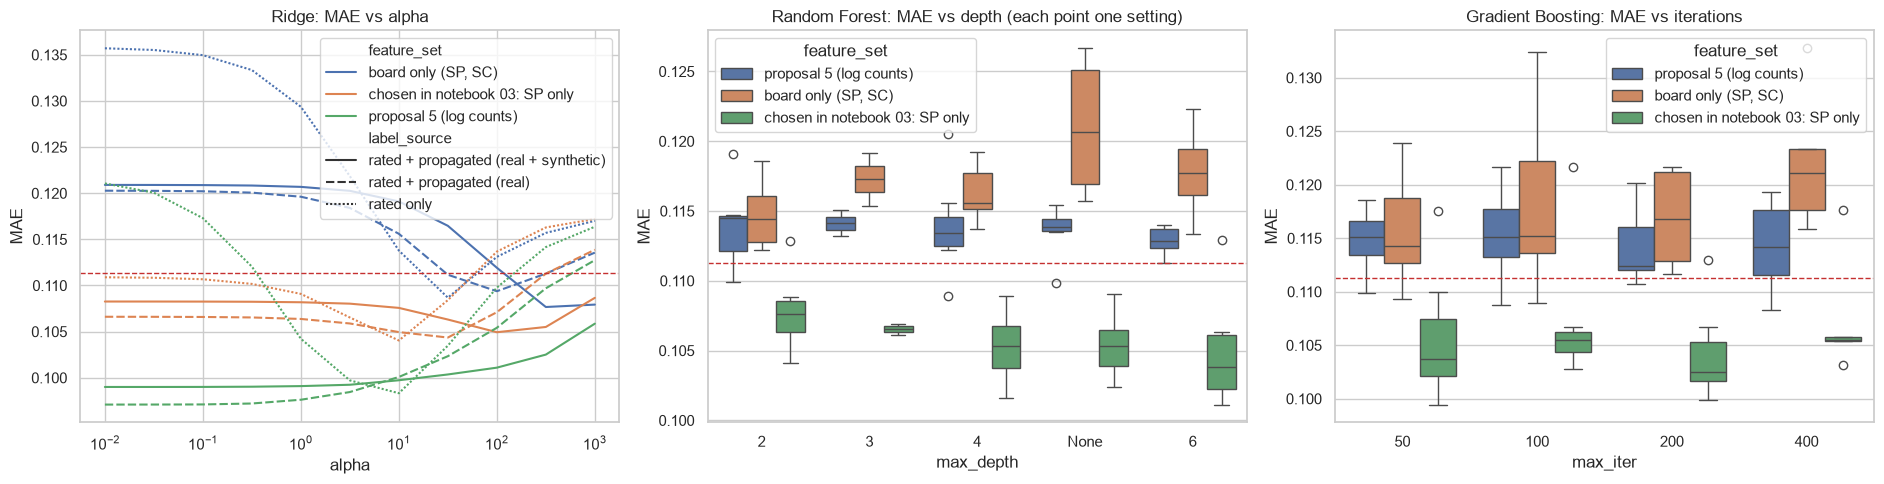

min  median    max
model             feature_set                                         
Gradient Boosting board only (SP, SC)             0.109   0.116  0.133
                  chosen in notebook 03: SP only  0.099   0.104  0.122
                  proposal 5 (log counts)         0.108   0.115  0.122
Random Forest     board only (SP, SC)             0.112   0.116  0.127
                  chosen in notebook 03: SP only  0.101   0.106  0.113
                  proposal 5 (log counts)         0.109   0.114  0.121
Ridge             board only (SP, SC)             0.106   0.119  0.136
                  chosen in notebook 03: SP only  0.104   0.108  0.117
                  proposal 5 (log counts)         0.096   0.100  0.121

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
r = tune[tune.model == "Ridge"].copy()
r["alpha"] = r.params.map(lambda s: json.loads(s)["alpha"])
sns.lineplot(data=r.groupby(["feature_set", "alpha", "label_source"]).MAE.mean().reset_index(), x="alpha", y="MAE", hue="feature_set", style="label_source", ax=axes[0])
axes[0].set(xscale="log", title="Ridge: MAE vs alpha")
f = tune[tune.model == "Random Forest"].copy()
f["max_depth"] = f.params.map(lambda s: str(json.loads(s)["max_depth"]))
sns.boxplot(data=f.groupby(["config_id", "feature_set", "max_depth"]).MAE.mean().reset_index(), x="max_depth", y="MAE", hue="feature_set", ax=axes[1])
axes[1].set(title="Random Forest: MAE vs depth (each point one setting)")
g = tune[tune.model == "Gradient Boosting"].copy()
g["max_iter"] = g.params.map(lambda s: json.loads(s)["max_iter"])
sns.boxplot(data=g.groupby(["config_id", "feature_set", "max_iter"]).MAE.mean().reset_index(), x="max_iter", y="MAE", hue="feature_set", ax=axes[2])
axes[2].set(title="Gradient Boosting: MAE vs iterations")
for a in axes:
    a.axhline(ref.min(), color="#c53030", ls="--", lw=1)
plt.tight_layout()
plt.show()
tune.groupby(["model", "feature_set", "config_id"]).MAE.mean().groupby(["model", "feature_set"]).agg(["min", "median", "max"]).round(3)

## 6. Under- and over-fitting: learning curves

For the best feature set of each model: train on 25%, 50%, 75% and 100% of the training rows (three random draws, at least 4 rows) and
compare the error on the training rows with the error on the validation rows.

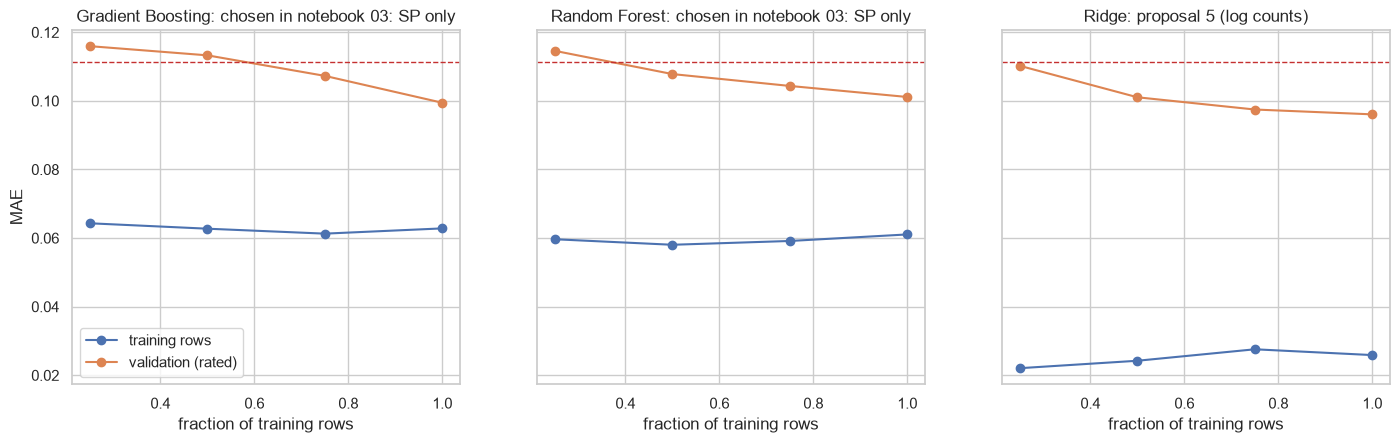

,model,fraction of training rows,train MAE,validation MAE
0,Gradient Boosting,0.25,0.064,0.116
1,Gradient Boosting,0.50,0.063,0.113
2,Gradient Boosting,0.75,0.061,0.107
3,Gradient Boosting,1.00,0.063,0.099
4,Random Forest,0.25,0.060,0.115
5,Random Forest,0.50,0.058,0.108
6,Random Forest,0.75,0.059,0.104
7,Random Forest,1.00,0.061,0.101
8,Ridge,0.25,0.022,0.110
9,Ridge,0.50,0.024,0.101


In [9]:
def best_config(model):
    name = summary.reset_index().query("model == @model").sort_values("inner_MAE").iloc[0].feature_set
    fs_i = [s[0] for s in SETS].index(name)
    g = tune[(tune.model == model) & (tune.feature_set == name)].groupby("config_id").MAE.mean()
    row = tune[tune.config_id == g.idxmin()].iloc[0]
    return fs_i, json.loads(row.params), row.label_source, row.weight


curves, rng = [], np.random.RandomState(SEED)
for model in SPACE:
    fs_i, params, label_source, weight = best_config(model)
    for frac in (0.25, 0.5, 0.75, 1.0):
        for draw in range(3 if frac < 1 else 1):
            tr, va = [], []
            for ci in range(len(combos)):
                X, y, w, Xv, yv, act, rid = get_data(ci, fs_i, label_source, weight)
                k = max(4, int(round(frac * len(y))))
                idx = rng.choice(len(y), min(k, len(y)), replace=False) if frac < 1 else np.arange(len(y))
                m = fit_model(make_model(model, params, X.shape[1]), model, X[idx], y[idx], w[idx])
                tr.append(np.average(np.abs(np.clip(m.predict(X[idx]), 0, 1) - y[idx]), weights=w[idx]))
                va.append(np.abs(np.clip(m.predict(Xv), 0, 1) - yv).mean())
            curves.append((model, frac, np.mean(tr), np.mean(va)))
lc = pd.DataFrame(curves, columns=["model", "fraction of training rows", "train MAE", "validation MAE"]).groupby(["model", "fraction of training rows"]).mean().reset_index()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
for a, (model, g) in zip(axes, lc.groupby("model")):
    a.plot(g["fraction of training rows"], g["train MAE"], "o-", label="training rows")
    a.plot(g["fraction of training rows"], g["validation MAE"], "o-", label="validation (rated)")
    a.axhline(ref.min(), color="#c53030", ls="--", lw=1)
    a.set(title=f"{model}: {SETS[best_config(model)[0]][0]}", xlabel="fraction of training rows")
axes[0].set_ylabel("MAE")
axes[0].legend()
plt.show()
lc.round(3)

## 7. Save the choices and log

In [10]:
out = {}
for (model, fs), g in chosen.groupby(["model", "feature_set"]):
    out.setdefault(model, {})[fs] = {r.outer_test: {"params": json.loads(r.params), "label_source": r.label_source, "weight": float(r.weight),
                                                    "inner_MAE": round(float(r.inner_MAE), 4)} for r in g.itertuples()}
(F.results / "tuning_choices.json").write_text(json.dumps(out, indent=1))
for r in summary.reset_index().itertuples():
    log_run(F, "04_hyperparameter_tuning", r.model, f"{r.feature_set}; nested inner validation, mean of 5 outer folds", {"MAE": round(r.inner_MAE, 4), "SE": round(r.spread_over_folds, 4)})
print("saved training/results/tuning_choices.json and tuning_results.csv; logged to runs.csv")

saved training/results/tuning_choices.json and tuning_results.csv; logged to runs.csv


## 8. Reading the results

Tuned **inner-validation MAE** (mean over the 5 outer folds):

| Model | proposal 5 | board only (SP, SC) | story points only (chosen in 03) |
|---|---|---|---|
| Ridge | **0.107** | 0.117 | 0.117 |
| Random Forest | 0.110 | 0.119 | 0.108 |
| Gradient Boosting | 0.114 | 0.117 | 0.113 |

For reference, always predicting the mean scores 0.128 and the untuned Ridge on five features 0.111 (notebook 02).

- **No model gets close to the useful range.** The best tuned score (0.107) is 16% better than guessing the mean and no better than the
  untuned baseline (0.111). Every combination lies in 0.107-0.119.
- **The spread between folds is large** (0.014-0.031, compared with 0.007-0.015 for Consistency): which groups end up in training matters
  more than the choice of model.
- **Under- and over-fitting.** Ridge fits its training rows far better than its validation rows (0.026 vs 0.096), a clear over-fit given 9-15
  rated rows and five features. Forest and boosting have a smaller but still wide gap (0.060 vs 0.100). All three validation curves are still
  falling at 100% of the data, so more labels would help.
- **Settings.** The best setting per model is 0.096-0.104, the median 0.100-0.119, and a few reach 0.12-0.14: little room for tuning to help.
- The tuned scores are best-of-many on the same validation groups and therefore optimistic; notebook 05 removes that bias.

Saved: `training/results/tuning_choices.json`, `tuning_results.csv`. Next: **05. Model comparison**.